In [1]:

import pandas as pd

df = pd.read_csv("StudentPerformanceFactors.csv")

df.head()


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [4]:

def desc(sample, column):
    data = sample[column]

    print("Mean:", data.mean())
    print("Median:", data.median())
    print("Mode:", data.mode()[0])
    print("Minimum:", data.min())
    print("Maximum:", data.max())
    print("Standard Deviation:", data.std())
    print("Variance:", data.var())

desc(df, "Exam_Score")


Mean: 67.23565914938702
Median: 67.0
Mode: 68
Minimum: 55
Maximum: 101
Standard Deviation: 3.890455781261732
Variance: 15.135646185952833


In [5]:
random_sample = df.sample(n=150, random_state=42)

desc(random_sample, "Exam_Score")


Mean: 67.40666666666667
Median: 67.0
Mode: 67
Minimum: 55
Maximum: 89
Standard Deviation: 4.122449045137358
Variance: 16.994586129753916


In [6]:
sys_sample = df.iloc[::5]

desc(sys_sample, "Exam_Score")


Mean: 67.13086232980334
Median: 67.0
Mode: 66
Minimum: 57
Maximum: 101
Standard Deviation: 3.859998942642619
Variance: 14.899591837202138


In [7]:
df["Exam_Score"].describe()

count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

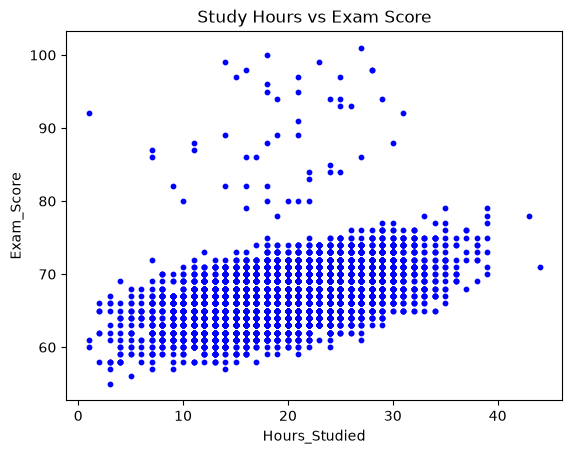

In [8]:
import matplotlib.pyplot as plt
df.plot.scatter(x="Hours_Studied", y="Exam_Score", s=10, c="blue")
plt.title("Study Hours vs Exam Score")
plt.show()


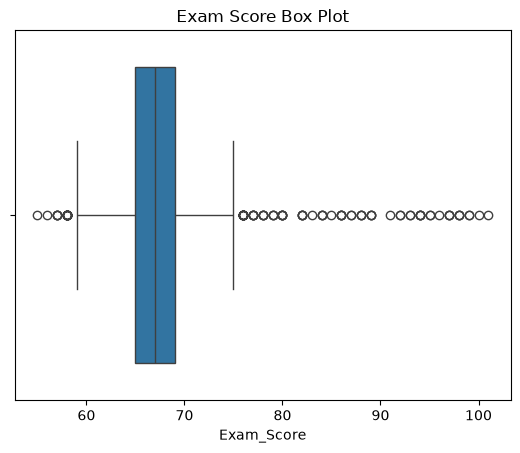

In [9]:
import seaborn as sns
sns.boxplot(x=df["Exam_Score"])
plt.title("Exam Score Box Plot")
plt.show()

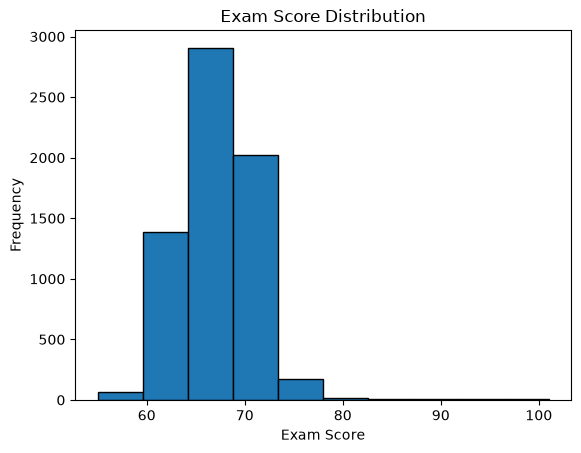

In [10]:
plt.hist(df["Exam_Score"], bins=10, edgecolor="black")
plt.xlabel("Exam Score")
plt.ylabel("Frequency")
plt.title("Exam Score Distribution")
plt.show()

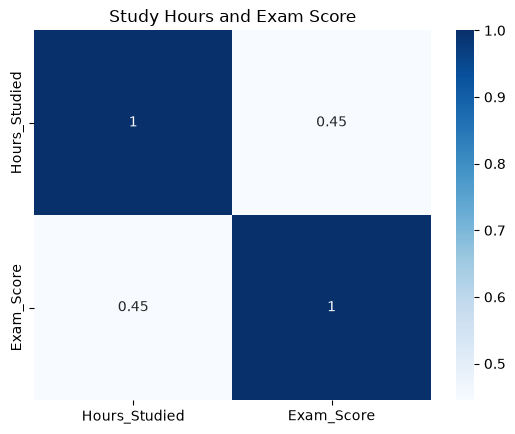

In [11]:
corr = df[["Hours_Studied", "Exam_Score"]].corr()
sns.heatmap(corr, annot=True, cmap="Blues")
plt.title("Study Hours and Exam Score")
plt.show()

In [12]:
from scipy.stats import pearsonr
data = df[["Hours_Studied", "Exam_Score"]].dropna()
r, p = pearsonr(data["Hours_Studied"], data["Exam_Score"])
print("Pearson:", r)
print("P-value:", p)

Pearson: 0.44545495407528185
P-value: 1.28635e-319


In [13]:
from scipy.stats import spearmanr
r, p = spearmanr(data["Hours_Studied"], data["Exam_Score"])
print("Spearman:", r)
print("P-value:", p)

Spearman: 0.48095596242825545
P-value: 0.0


In [14]:
import scipy
from scipy.stats import shapiro
avg = df["Exam_Score"].mean()
scores = random_sample["Exam_Score"]
print("Population Mean:", avg)
print("Sample Mean:", scores.mean())
print("Shapiro Test:", shapiro(scores))
print("T-test:", scipy.stats.ttest_1samp(scores, avg))

Population Mean: 67.23565914938702
Sample Mean: 67.40666666666667
Shapiro Test: ShapiroResult(statistic=np.float64(0.9463399252134252), pvalue=np.float64(1.646079504622277e-05))
T-test: TtestResult(statistic=np.float64(0.5080489230175042), pvalue=np.float64(0.6121703345045606), df=np.int64(149))
